# 15 — CSTR OCP and receding-horizon NMPC

**Objectives.** Build a scaled multiple-shooting OCP, apply the first input, shift the horizon, and warm-start the next solve. NMPC repeats: measure/estimate state → update parameter → solve → apply one control → shift. Bounds are safety/model-validity constraints, not tuning weights.


In [4]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Formulate the nonlinear model-predictive controller

This cell builds a fresh MX RK4 model and a multiple-shooting Opti problem.
The current plant state is an Opti parameter, which can change between
control updates without rebuilding the NLP. State and input bounds define
the intended operating region. `diag` scales heterogeneous physical units,
`repmat` repeats the target over the horizon, and `sumsqr` creates the
quadratic tracking penalties.

At each control update, the NMPC problem is

$$
\begin{aligned}
\min_{x,u}\quad &
\sum_{k=0}^{N}\|S_x(x_k-x_s)\|_2^2
+0.1\sum_{k=0}^{N-1}
\left|\frac{u_k-u_s}{10}\right|^2\\
\text{s.t.}\quad &x_0=x_{\mathrm{measured}},\\
&x_{k+1}=F_{\mathrm{RK4}}(x_k,u_k,d_s),\\
&0\le C_{A,k}\le12,\quad285\le T_k\le360,\\
&285\le u_k\le315,
\end{aligned}
$$

where $S_x=\operatorname{diag}(1/0.5,1/5)$.


In [5]:
import casadi as ca
import matplotlib.pyplot as plt
import numpy as np

from casadi_tutorial.models.cstr import CSTRParameters, CSTRSystem

parameters = CSTRParameters()
system = CSTRSystem(parameters, symbolic_type="MX")
horizon_steps = 10
step_size = 0.05
discrete_dynamics = system.discrete_dynamics(step_size)

optimization = ca.Opti()
x = optimization.variable(2, horizon_steps + 1)
u = optimization.variable(1, horizon_steps)
x_initial = optimization.parameter(2)
optimization.subject_to(x[:, 0] == x_initial)

for index in range(horizon_steps):
    optimization.subject_to(
        x[:, index + 1]
        == discrete_dynamics(
            x[:, index],
            u[:, index],
            parameters.nominal_disturbance,
        )
    )

optimization.subject_to(optimization.bounded(0, x[0, :], 12))
optimization.subject_to(optimization.bounded(285, x[1, :], 360))
optimization.subject_to(optimization.bounded(285, u, 315))

x_scaling = ca.diag(ca.DM([1 / 0.5, 1 / 5]))
x_target = ca.repmat(
    ca.DM(parameters.nominal_state),
    1,
    horizon_steps + 1,
)
x_error = x_scaling @ (x - x_target)
u_error = (u - parameters.nominal_jacket_temperature) / 10
optimization.minimize(ca.sumsqr(x_error) + 0.1 * ca.sumsqr(u_error))
optimization.solver(
    "ipopt",
    {"print_time": False},
    {"print_level": 0, "max_iter": 300, "tol": 1e-7},
)

### Execute the receding-horizon feedback loop

The current state parameter is updated with `set_value`, then the NLP is
solved. Only the first optimized jacket temperature is applied to the
discrete plant model. The previous optimal trajectories are shifted with
`set_initial` to warm-start the following solve; these initial values guide
IPOPT but do not constrain the next optimum.

The feedback policy implemented by NMPC is

$u^*(x_k)=\arg\min_u J(x,u;x_k),
\qquad
u_k=u^*_0(x_k),$

followed by the plant update

$$
x_{k+1}=F_{\mathrm{RK4}}(x_k,u_k,d_s).
$$

The optimize–apply-first-input–shift cycle is repeated five times, and the
final assertions check solver success and finite closed-loop states.

The closed-loop plots show both CSTR state components $x(t)$ and the applied manipulated input $u(t)$ at each receding-horizon update.


closed-loop x: [[  8.8195     310.267     ]
 [  8.80936761 310.38060533]
 [  8.7993509  310.48417699]
 [  8.78948232 310.57847934]
 [  8.77978988 310.66422415]
 [  8.77029752 310.74207415]] applied u: [303.31904556 302.8121397  302.34541935 301.91624572 301.52211325]


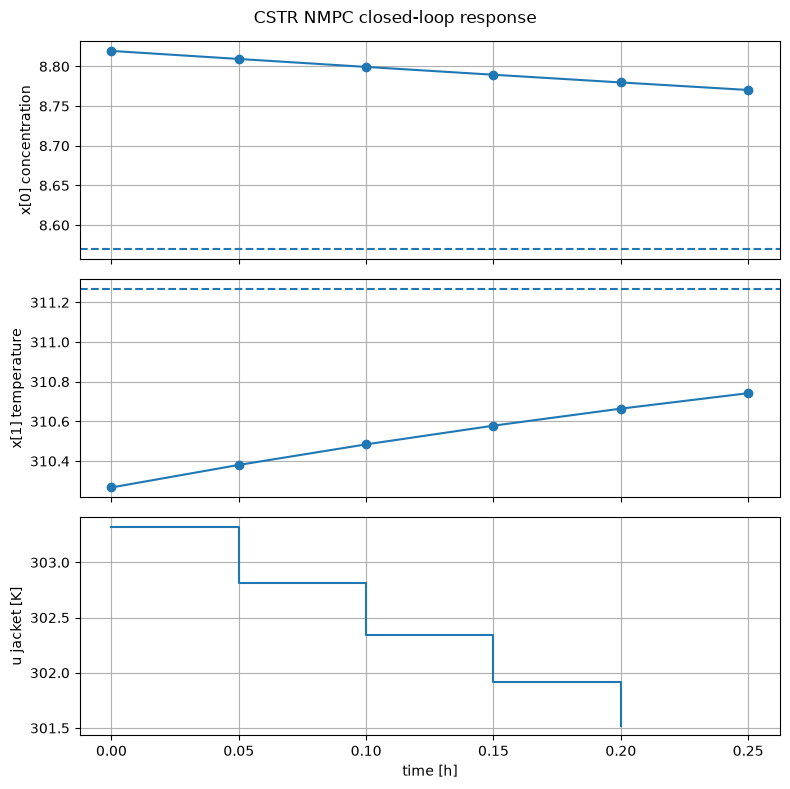

In [6]:
x_current = parameters.nominal_state + np.array([0.25, -1.0])
x_closed_loop = [x_current.copy()]
u_applied = []

for iteration in range(5):
    optimization.set_value(x_initial, x_current)
    if iteration == 0:
        optimization.set_initial(
            x,
            np.tile(x_current[:, None], (1, horizon_steps + 1)),
        )
        optimization.set_initial(u, parameters.nominal_input)

    solution = optimization.solve()
    last_solve_succeeded = solution.stats()["success"]
    x_predicted = solution.value(x)
    u_predicted = np.atleast_2d(solution.value(u))

    u_current = float(u_predicted[0, 0])
    u_applied.append(u_current)
    x_current = np.asarray(
        discrete_dynamics(
            x_current,
            [u_current],
            parameters.nominal_disturbance,
        ).full()
    ).ravel()
    x_closed_loop.append(x_current.copy())

    optimization.set_initial(
        x,
        np.column_stack([x_predicted[:, 1:], x_predicted[:, -1]]),
    )
    optimization.set_initial(
        u,
        np.column_stack([u_predicted[:, 1:], u_predicted[:, -1]]),
    )

x_closed_loop = np.asarray(x_closed_loop)
u_applied = np.asarray(u_applied)
print("closed-loop x:", x_closed_loop, "applied u:", u_applied)
assert last_solve_succeeded
assert np.isfinite(x_closed_loop).all()

x_time = step_size * np.arange(len(x_closed_loop))
u_time = x_time[:-1]
figure, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 8))
axes[0].plot(x_time, x_closed_loop[:, 0], marker="o")
axes[0].axhline(parameters.nominal_concentration, linestyle="--")
axes[0].set_ylabel("x[0] concentration")
axes[1].plot(x_time, x_closed_loop[:, 1], marker="o")
axes[1].axhline(parameters.nominal_temperature, linestyle="--")
axes[1].set_ylabel("x[1] temperature")
axes[2].step(u_time, u_applied, where="post")
axes[2].set(xlabel="time [h]", ylabel="u jacket [K]")
for axis in axes:
    axis.grid(True)
figure.suptitle("CSTR NMPC closed-loop response")
figure.tight_layout()
plt.show()

Warm starts reuse primal trajectories; lower-level interfaces can also reuse `lam_x0`/`lam_g0` when solver options support it. If the measured state violates a hard path bound, the NLP is infeasible at node zero—use a deliberate soft constraint, not a mysterious tolerance increase.

**Debug checklist:** evaluate dynamics at the initial guess, plot each residual block, scale states/inputs, inspect `return_status`, and compare predicted versus applied dynamics. **Recap:** NMPC reliability comes from formulation, initialization, and validation around the solver call.
